# C3 reading step 4 — Final visual system and decision record
**Group 67 | Ian Spikin Thomas · Juan Pablo Molina**

**Question:** Which DataCo regions share recording and coverage profiles, and what should a BI analyst check before comparing regional KPIs?

This notebook implements the three assessed W3 redesigns using the rounded, saved aggregate outputs of the original C2 notebook (cells 9, 14, 16). It does not reload transactions or refit the model. The historical W3 exploratory scatter and Ward dendrogram are available on pages 9–10 of the W3 PDF; Ward agreement of 1.000 is reported there, not independently rerun here. The final presentation relies on the three reproducible redesigns and W2 diagnostic.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from IPython.display import display
# Shared visual system adapted from W3 p.2; typography uses portable DejaVu Sans.
C = ['#286A96','#16867E','#7952A0']; AMBER='#DB952C'; SLATE='#97A6B8'; INK='#243447'
TERCILES=['#D9E1EC','#8D9DB0','#2C4864']
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.spines.top':False,'axes.spines.right':False,'axes.labelcolor':INK,'text.color':INK,'figure.dpi':130,'axes.titleweight':'bold'})
# Transcribed rounded summaries from original C2 cells 9, 14 and 16; cross-checked against W3 pp.3,5,7.
scores=pd.Series([.6125,.6235,.5959,.5827,.5394],index=[2,3,4,5,6],name='silhouette')
z=pd.DataFrame([[-.67,.61,-.88],[.98,-.02,1.21],[.70,-1.98,1.03]],index=['C0','C1','C2'],columns=['Order volume (log10)','Rows per order','Date span'])
counts=pd.DataFrame([[8,5,0],[0,1,5],[0,1,3]],index=z.index,columns=['Low','Middle','High'])
assert scores.idxmax()==3 and counts.sum(axis=1).tolist()==[13,6,4] and counts.values.sum()==23
display(scores.to_frame(),z,counts)

,silhouette
2,0.6125
3,0.6235
4,0.5959
5,0.5827
6,0.5394


,Order volume (log10),Rows per order,Date span
C0,-0.67,0.61,-0.88
C1,0.98,-0.02,1.21
C2,0.70,-1.98,1.03


,Low,Middle,High
C0,8,5,0
C1,0,1,5
C2,0,1,3


## 1. Select K — W3 chart 1
Discrete bars replace the line; zero baseline, exact labels and a highlighted maximum make the task of identifying the largest observed silhouette easier. K=3 is only narrowly ahead of K=2; this is not predictive accuracy or proof of stability.

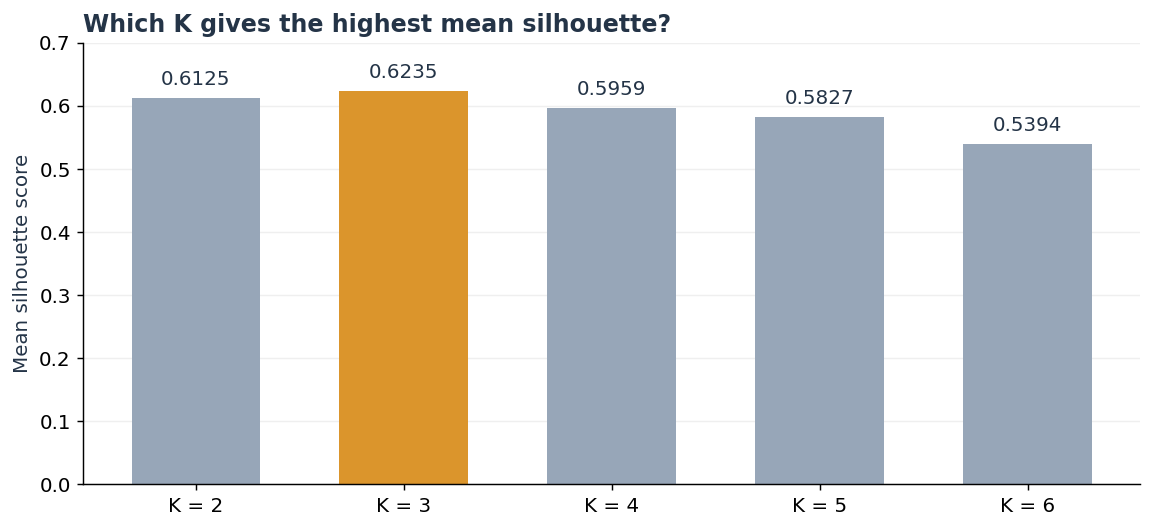

In [2]:
fig,ax=plt.subplots(figsize=(9,4.2)); bars=ax.bar([f'K = {k}' for k in scores.index],scores,color=[AMBER if k==3 else SLATE for k in scores.index],width=.62)
ax.bar_label(bars,labels=[f'{x:.4f}' for x in scores],padding=5); ax.set_ylim(0,.7); ax.set_ylabel('Mean silhouette score'); ax.set_title('Which K gives the highest mean silhouette?',loc='left'); ax.grid(axis='y',alpha=.2); ax.set_axisbelow(True); fig.tight_layout(); plt.show()

## 2. Compare profiles — W3 chart 2
A fixed diverging scale centered on zero replaces the sequential map. Signed values and cluster sizes provide non-color cues. Z-scores are dimensionless; negative means below the regional mean, not negative sales.

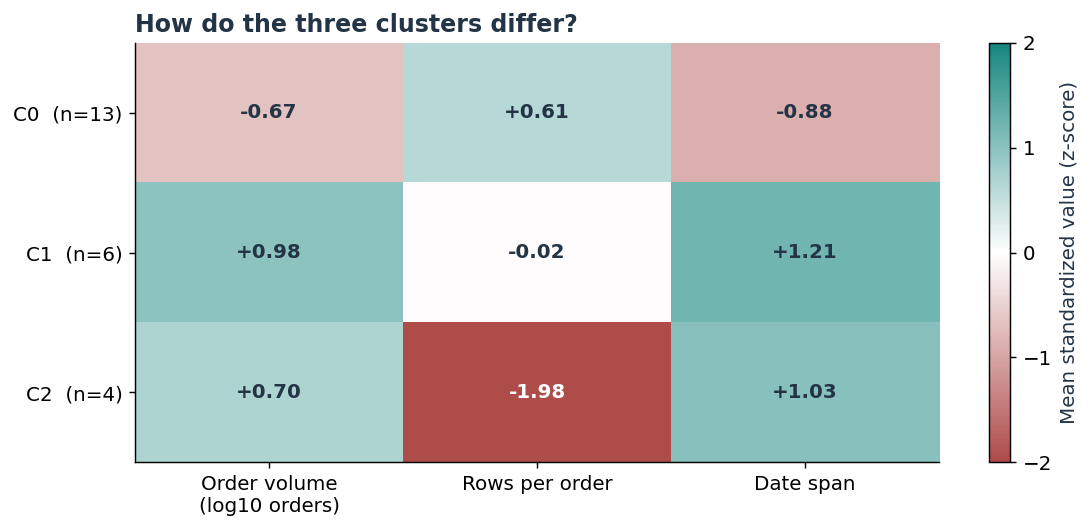

In [3]:
fig,ax=plt.subplots(figsize=(9,4.2)); cmap=LinearSegmentedColormap.from_list('profile',['#AE4B49','#FFFFFF','#16867E']); im=ax.imshow(z,cmap=cmap,norm=TwoSlopeNorm(vmin=-2,vcenter=0,vmax=2),aspect='auto')
ax.set_xticks(range(3),['Order volume\n(log10 orders)','Rows per order','Date span']); ax.set_yticks(range(3),[f'{c}  (n={n})' for c,n in zip(z.index,counts.sum(axis=1))]);
for i in range(3):
 for j in range(3):
  v=z.iloc[i,j]; ax.text(j,i,f'{v:+.2f}',ha='center',va='center',color='white' if abs(v)>1.3 else INK,fontweight='bold')
fig.colorbar(im,ax=ax,label='Mean standardized value (z-score)',ticks=[-2,-1,0,1,2]); ax.set_title('How do the three clusters differ?',loc='left'); fig.tight_layout(); plt.show()

## 3. Compare with a simple rule — W3 chart 3
Use 100% stacked horizontal bars rather than a count heatmap to compare shares despite unequal cluster sizes. Counts and totals preserve magnitude. ARI = 0.361 is agreement, not accuracy. C1 and C2 are predominantly high-volume but differ in recording structure.

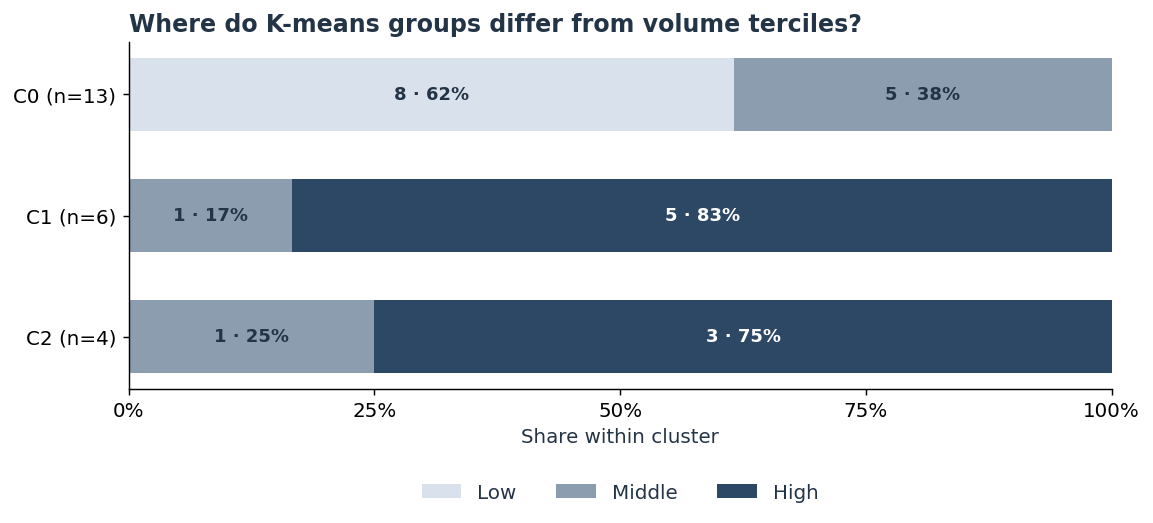

In [4]:
fig,ax=plt.subplots(figsize=(9,4.3)); shares=counts.div(counts.sum(axis=1),axis=0)*100; left=np.zeros(3)
for j,col in enumerate(counts.columns):
 vals=shares[col].to_numpy(); ax.barh(z.index,vals,left=left,color=TERCILES[j],label=col,height=.6)
 for i,v in enumerate(vals):
  if v>0: ax.text(left[i]+v/2,i,f'{counts.iloc[i,j]} · {v:.0f}%',ha='center',va='center',color='white' if j==2 else INK,fontsize=10,fontweight='bold')
 left+=vals
ax.set_yticks(range(3),[f'{c} (n={n})' for c,n in zip(z.index,counts.sum(axis=1))]); ax.invert_yaxis(); ax.set_xlim(0,100); ax.set_xticks([0,25,50,75,100],[f'{v}%' for v in [0,25,50,75,100]]); ax.set_xlabel('Share within cluster'); ax.set_title('Where do K-means groups differ from volume terciles?',loc='left'); ax.legend(loc='upper center',bbox_to_anchor=(.5,-.22),ncol=3,frameon=False); fig.tight_layout(); plt.show()

## 4. Decision and development record
| Stage | Decision and evidence | Effect on final message |
|---|---|---|
| W1/C1 | Selected commercial question rather than late-delivery route; identified item-level observation and regional KPI. See notebook 01, sections 1, 6 and 8. | Focus on regional comparability, not logistics prediction. |
| W2 | Retained status exclusions, checked duplicate IDs and numeric domains; 1,475 category labels had whitespace. Monthly audit revealed a structural break; no month shared by all five largest regions. See notebook 02, sections 4–5. | Avoid unconditional regional rankings and distinguish observed pattern from cause. |
| C2 | Addressed W2 README feedback and clarified that October pattern does not prove a migration. Kept descriptive K-means with seed 67, n_init=20; used the same 23 regions for volume-tercile reference. See notebook 03, original cells 1, 3, 5, 7, 9, 14, 16. | Three audit profiles; no predictive accuracy claim. |
| W3 | Replaced line with bars, sequential heatmap with zero-centered heatmap, count heatmap with composition bars. W3 pp.3–8. | Visual encoding matches identification/comparison tasks; same values retained. |
| C3 | Consolidated saved evidence; removed transaction file, corrected October wording, implemented final visual code using saved summaries. | Reviewer can read results without data downloads or code execution. |

**Recommendation:** compare within profiles as a first screening step, audit C2 (Oceania, South Asia, Eastern Asia, Southeast Asia), and check active-month coverage before comparing any KPIs. Within-profile membership alone does not establish comparability. Ask for source-system logs and test sensitivity to scaling/features or region resampling before operational use.

**Contributions (documented in C2):** Ian Spikin Thomas implemented validation, aggregation, model selection, K-means, baseline and plots. Juan Pablo Molina reviewed framing, method, interpretation, limitations and edited the brief/presentation. The C3 speaking allocation is proposed, not a claim of additional completed individual work. No separate W3 instructor feedback was provided in the supplied files.

**AI disclosure:** AI was used in earlier stages for drafting and code suggestions (see source notebooks), and in C3 to consolidate the submission, implement visual redesigns from saved results, and draft slides and rehearsal notes. Team members must review the evidence and confirm their own contributions before submission. No live AI during defense.